### Data Importing

In [28]:
import pandas as pd
File  = pd.read_csv("Household_Data.csv")
Ag_dec_Sociodemo = pd.DataFrame(File)
Ag_dec_Sociodemo.drop(columns = "Unnamed: 0", axis = 1, inplace = True)
Ag_dec_Sociodemo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 118 entries, 0 to 117
Data columns (total 25 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   Respondent's Name                                   118 non-null    object 
 1   Municipality                                        118 non-null    object 
 2   Ward                                                116 non-null    float64
 3   Gender                                              117 non-null    object 
 4   Age                                                 115 non-null    float64
 5   Family size                                         115 non-null    float64
 6   Educational qualification                           117 non-null    object 
 7   Primary occupation                                  116 non-null    object 
 8   Ethnicity                                           117 non-null    object 
 9  

For our purpose, we shall observe how the factors being Municipality (Location), Sex, Age, Caste, Family size, Educational Qualification Primary occupation, and Availability of sufficient water for irrigation representing socio-ecological profile of the repsondents affect crop choices. Although the respondents may not be a household head, the fact that most of them are farmers (i.e., 87% conveyed Agriculture as their primary occupation) provides a sufficient ground for them to qualify as individuals of the household that at least take significant agricultural decisions constituting nature of crop to be planted in their farmland  

In [29]:
Ag_dec_SD = Ag_dec_Sociodemo[["Municipality",
                             "Gender",
                             "Age",
                             "Ethnicity",
                             "Family size",
                             "Educational qualification",
                             "Primary occupation",
                             "Availability of sufficient water for irrigation",
                             "Crop Choice"]]
Ag_dec_SD.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 118 entries, 0 to 117
Data columns (total 9 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   Municipality                                     118 non-null    object 
 1   Gender                                           117 non-null    object 
 2   Age                                              115 non-null    float64
 3   Ethnicity                                        117 non-null    object 
 4   Family size                                      115 non-null    float64
 5   Educational qualification                        117 non-null    object 
 6   Primary occupation                               116 non-null    object 
 7   Availability of sufficient water for irrigation  114 non-null    object 
 8   Crop Choice                                      117 non-null    object 
dtypes: float64(2), object(7)
memory u

### Data Preprocessing

#### Data preparing

In [30]:
#Lets feature engineer a geographical signficance of the municipality as we are aware of the stark difference in the geography of the 
# study areas 
Ag_dec_SD["Geography"] = Ag_dec_SD["Municipality"].replace("Bheriganga (Siwalik)", "Urban")
Ag_dec_SD["Geography"].replace(["Budhinanda (High-Mountain)", "Bhairabi (Mid-Hill)"], "Remote", inplace = True)
Ag_dec_SD["Geography"].value_counts()

C:\Users\prien\AppData\Local\Temp\ipykernel_8744\2988562239.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Ag_dec_SD["Geography"] = Ag_dec_SD["Municipality"].replace("Bheriganga (Siwalik)", "Urban")
C:\Users\prien\AppData\Local\Temp\ipykernel_8744\2988562239.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace 

Geography
Remote    75
Urban     43
Name: count, dtype: int64

In [31]:
#Deleting the missing value since we have only few null records.  
Ag_dec_SD.dropna(inplace = True)

C:\Users\prien\AppData\Local\Temp\ipykernel_8744\1759459133.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Ag_dec_SD.dropna(inplace = True)


In [32]:
#Now, preparing the compiled variable
Ag_dec_SD = Ag_dec_SD[["Age", "Gender", "Ethnicity", "Family size", "Educational qualification", "Primary occupation",
                       "Availability of sufficient water for irrigation", "Geography", "Crop Choice"]]
Ag_dec_SD.info()
 

<class 'pandas.core.frame.DataFrame'>
Index: 108 entries, 0 to 117
Data columns (total 9 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   Age                                              108 non-null    float64
 1   Gender                                           108 non-null    object 
 2   Ethnicity                                        108 non-null    object 
 3   Family size                                      108 non-null    float64
 4   Educational qualification                        108 non-null    object 
 5   Primary occupation                               108 non-null    object 
 6   Availability of sufficient water for irrigation  108 non-null    object 
 7   Geography                                        108 non-null    object 
 8   Crop Choice                                      108 non-null    object 
dtypes: float64(2), object(7)
memory usage:

In [33]:
Ag_dec_SD["Crop Choice"].replace({"Planting of mix of hybrid and indigenous species of crops": "Planting of mix of indigenous and improved species of crops",
                                  "Planting of hybrid species of crops only": "Planting of improved spcies of crops only"}, inplace = True)
Ag_dec_SD["Crop Choice"].value_counts()

C:\Users\prien\AppData\Local\Temp\ipykernel_8744\3484777350.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  Ag_dec_SD["Crop Choice"].replace({"Planting of mix of hybrid and indigenous species of crops": "Planting of mix of indigenous and improved species of crops",


Crop Choice
Planting of mix of indigenous and improved species of crops    52
Planting of indigenous species of crops only                   49
Planting of improved spcies of crops only                       7
Name: count, dtype: int64

#### Spatial Significance of Crop Choice (Analysis of Association)

In [34]:
#Visualizing crop choices being made across the three different locations with different physiography 
Crosstable = pd.crosstab(Ag_dec_SD["Geography"], Ag_dec_SD["Crop Choice"])
Crosstable
# The values under the column representing the adoption of hybrid crops only has a null value for Bhairabi. Since, the 
# accuracy of Chi-square test suffers with the presence of null values, we shall combine the two possible columns to eliminate values
# that are null

Crop Choice,Planting of improved spcies of crops only,Planting of indigenous species of crops only,Planting of mix of indigenous and improved species of crops
Geography,,,
Remote,0,43,27
Urban,7,6,25


In [35]:
#combining the value with a cell with a zero by creating a new dataframe
Spatial_Analysis = Ag_dec_SD[["Geography", "Crop Choice"]]
Spatial_Analysis["Crop Choice"] = Spatial_Analysis["Crop Choice"].replace(["Planting of mix of hybrid and indigenous species of crops",
                                                                         "Planting of hybrid species of crops only"],
                                                                         "Planting of hybrid crops (either alone or mixed)")
Crosstable = pd.crosstab(Spatial_Analysis["Geography"], Spatial_Analysis["Crop Choice"])
Crosstable

C:\Users\prien\AppData\Local\Temp\ipykernel_8744\1468321570.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Spatial_Analysis["Crop Choice"] = Spatial_Analysis["Crop Choice"].replace(["Planting of mix of hybrid and indigenous species of crops",


Crop Choice,Planting of improved spcies of crops only,Planting of indigenous species of crops only,Planting of mix of indigenous and improved species of crops
Geography,,,
Remote,0,43,27
Urban,7,6,25


In [36]:
#Now performing the chi-square test to test for association between geography and crop choice
import scipy.stats
print(scipy.stats.chi2_contingency(Crosstable, correction = False))
#the association is quite significant given that the p-value of the test is significantly less than 0.05. In fact, the association can also
#be visually insepected to be significant

Chi2ContingencyResult(statistic=np.float64(27.991645518820597), pvalue=np.float64(8.350094795459992e-07), dof=2, expected_freq=array([[ 4.53703704, 31.75925926, 33.7037037 ],
       [ 2.46296296, 17.24074074, 18.2962963 ]]))


#### Preprocessing the independent variables

In [37]:
#Now breaking our dataframe into independent and target datasets as we begin our preprocessing task
Ag_dec_SD_ind = Ag_dec_SD.drop(columns = "Crop Choice", axis=1)
Ag_dec_SD_ind.info()

<class 'pandas.core.frame.DataFrame'>
Index: 108 entries, 0 to 117
Data columns (total 8 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   Age                                              108 non-null    float64
 1   Gender                                           108 non-null    object 
 2   Ethnicity                                        108 non-null    object 
 3   Family size                                      108 non-null    float64
 4   Educational qualification                        108 non-null    object 
 5   Primary occupation                               108 non-null    object 
 6   Availability of sufficient water for irrigation  108 non-null    object 
 7   Geography                                        108 non-null    object 
dtypes: float64(2), object(6)
memory usage: 7.6+ KB


In [38]:
x_value = Ag_dec_SD_ind
y_value = Ag_dec_SD["Crop Choice"]
#Before we preprocessed our data, it is essential to split them into training, evaluation, and testing batch to avoid data snooping
#The split shall be based on approximately 60:20:20 basis as we have a very small sample size
from sklearn.model_selection import train_test_split
x_train, x_eval_test, y_train, y_eval_test = train_test_split(x_value,
                                                              y_value,
                                                              test_size = 0.4, 
                                                              random_state = 0,
                                                              stratify = y_value) 
x_eval, x_test, y_eval, y_test = train_test_split(x_eval_test,
                                                    y_eval_test,
                                                    test_size = 0.5, 
                                                    random_state = 0,
                                                    stratify = y_eval_test) 

print(x_train.shape[0], x_eval.shape[0], x_test.shape[0], y_train.shape[0], y_eval.shape[0], y_test.shape[0])

64 22 22 64 22 22


In [39]:
x_train_scaled = x_train[["Age", "Family size"]]
x_eval_scaled = x_eval[["Age", "Family size"]]
x_test_scaled = x_test[["Age", "Family size"]]
x_train_scaled.info()

<class 'pandas.core.frame.DataFrame'>
Index: 64 entries, 32 to 41
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          64 non-null     float64
 1   Family size  64 non-null     float64
dtypes: float64(2)
memory usage: 1.5 KB


In [40]:
# Standardizing the Age and family size values
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

x_train_scaled = pd.DataFrame(scaler.fit_transform(x_train_scaled), columns = x_train_scaled.columns)
x_eval_scaled = pd.DataFrame(scaler.transform(x_eval_scaled), columns = x_train_scaled.columns)
x_test_scaled = pd.DataFrame(scaler.transform(x_test_scaled), columns = x_train_scaled.columns)

x_train_scaled.head()

,Age,Family size
0,-1.226260,1.348128
1,1.377000,-0.133077
2,0.381636,-0.133077
3,0.228503,1.718429
4,0.534769,0.977827


In [41]:
#Seperating ordinal variables from nominal variables for independent dataframe batches
x_train_nominal = x_train.select_dtypes(include = "object")
x_eval_nominal = x_eval.select_dtypes(include = "object")
x_test_nominal = x_test.select_dtypes(include = "object")

x_train_nominal.info()

<class 'pandas.core.frame.DataFrame'>
Index: 64 entries, 32 to 41
Data columns (total 6 columns):
 #   Column                                           Non-Null Count  Dtype 
---  ------                                           --------------  ----- 
 0   Gender                                           64 non-null     object
 1   Ethnicity                                        64 non-null     object
 2   Educational qualification                        64 non-null     object
 3   Primary occupation                               64 non-null     object
 4   Availability of sufficient water for irrigation  64 non-null     object
 5   Geography                                        64 non-null     object
dtypes: object(6)
memory usage: 3.5+ KB


In [42]:
#Now preprocessing the nominal nature of the independent batches through onehotencoding
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(sparse_output = False,
                        handle_unknown= "ignore")  

x_train_nominal = pd.DataFrame(encoder.fit_transform(x_train_nominal),
                               columns = encoder.get_feature_names_out(x_train_nominal.columns.to_list()))

x_eval_nominal = pd.DataFrame(encoder.transform(x_eval_nominal),
                              columns = encoder.get_feature_names_out(x_eval_nominal.columns.to_list()))

x_test_nominal = pd.DataFrame(encoder.transform(x_test_nominal),
                              columns = encoder.get_feature_names_out(x_test_nominal.columns.to_list()))

In [43]:
# Now performing standardization on ONEd nominal variables
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

x_train_nominal = pd.DataFrame(scaler.fit_transform(x_train_nominal), columns = x_train_nominal.columns)
x_eval_nominal = pd.DataFrame(scaler.transform(x_eval_nominal), columns = x_eval_nominal.columns)
x_test_nominal = pd.DataFrame(scaler.transform(x_test_nominal), columns = x_test_nominal.columns)
x_test_nominal.head() 

,Gender_Female,Gender_Male,Ethnicity_Brahmin,Ethnicity_Chhetri,Ethnicity_Dalit,Ethnicity_Indigenous,Educational qualification_Graduation,Educational qualification_Higher Secondary,Educational qualification_Lower Secondary,Educational qualification_Undergraduate,Educational qualification_Unofficial Education,Primary occupation_Agriculture,Primary occupation_Foreign employment,Primary occupation_Government Service,Primary occupation_Trade,Primary occupation_Wage labor,Availability of sufficient water for irrigation_No,Availability of sufficient water for irrigation_Yes,Geography_Remote,Geography_Urban
0,-1.807392,1.807392,3.109126,-1.249000,-0.455573,-0.377964,-0.125988,-0.504878,4.509250,-0.179605,-1.538968,0.350438,-0.125988,-0.179605,-0.221766,-0.125988,-1.381699,1.381699,0.774597,-0.774597
1,-1.807392,1.807392,-0.321634,0.800641,-0.455573,-0.377964,-0.125988,-0.504878,-0.221766,-0.179605,0.649786,0.350438,-0.125988,-0.179605,-0.221766,-0.125988,0.723747,-0.723747,0.774597,-0.774597
2,-1.807392,1.807392,3.109126,-1.249000,-0.455573,-0.377964,-0.125988,-0.504878,-0.221766,-0.179605,0.649786,0.350438,-0.125988,-0.179605,-0.221766,-0.125988,-1.381699,1.381699,-1.290994,1.290994
3,-1.807392,1.807392,3.109126,-1.249000,-0.455573,-0.377964,-0.125988,1.980676,-0.221766,-0.179605,-1.538968,0.350438,-0.125988,-0.179605,-0.221766,-0.125988,0.723747,-0.723747,0.774597,-0.774597
4,-1.807392,1.807392,-0.321634,0.800641,-0.455573,-0.377964,-0.125988,-0.504878,-0.221766,-0.179605,0.649786,0.350438,-0.125988,-0.179605,-0.221766,-0.125988,0.723747,-0.723747,0.774597,-0.774597


In [44]:
#Ok now its time to merge the preprocessed independent datasets 
x_train_encoded = pd.concat([x_train_nominal, x_train_scaled], axis=1)
x_eval_encoded = pd.concat([x_eval_nominal, x_eval_scaled], axis=1)
x_test_encoded = pd.concat([x_test_nominal, x_test_scaled], axis=1)
x_train_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 22 columns):
 #   Column                                               Non-Null Count  Dtype  
---  ------                                               --------------  -----  
 0   Gender_Female                                        64 non-null     float64
 1   Gender_Male                                          64 non-null     float64
 2   Ethnicity_Brahmin                                    64 non-null     float64
 3   Ethnicity_Chhetri                                    64 non-null     float64
 4   Ethnicity_Dalit                                      64 non-null     float64
 5   Ethnicity_Indigenous                                 64 non-null     float64
 6   Educational qualification_Graduation                 64 non-null     float64
 7   Educational qualification_Higher Secondary           64 non-null     float64
 8   Educational qualification_Lower Secondary            64 non-null     flo

In [45]:
x_train_encoded.head()

,Gender_Female,Gender_Male,Ethnicity_Brahmin,Ethnicity_Chhetri,Ethnicity_Dalit,Ethnicity_Indigenous,Educational qualification_Graduation,Educational qualification_Higher Secondary,Educational qualification_Lower Secondary,Educational qualification_Undergraduate,...,Primary occupation_Foreign employment,Primary occupation_Government Service,Primary occupation_Trade,Primary occupation_Wage labor,Availability of sufficient water for irrigation_No,Availability of sufficient water for irrigation_Yes,Geography_Remote,Geography_Urban,Age,Family size
0,0.553283,-0.553283,-0.321634,-1.249000,-0.455573,2.645751,-0.125988,1.980676,-0.221766,-0.179605,...,7.937254,-0.179605,-0.221766,-0.125988,0.723747,-0.723747,-1.290994,1.290994,-1.226260,1.348128
1,0.553283,-0.553283,-0.321634,-1.249000,2.195036,-0.377964,-0.125988,-0.504878,-0.221766,-0.179605,...,-0.125988,-0.179605,-0.221766,-0.125988,0.723747,-0.723747,0.774597,-0.774597,1.377000,-0.133077
2,0.553283,-0.553283,3.109126,-1.249000,-0.455573,-0.377964,-0.125988,-0.504878,-0.221766,-0.179605,...,-0.125988,-0.179605,-0.221766,-0.125988,0.723747,-0.723747,0.774597,-0.774597,0.381636,-0.133077
3,0.553283,-0.553283,-0.321634,0.800641,-0.455573,-0.377964,-0.125988,-0.504878,-0.221766,-0.179605,...,-0.125988,-0.179605,-0.221766,-0.125988,0.723747,-0.723747,0.774597,-0.774597,0.228503,1.718429
4,-1.807392,1.807392,-0.321634,-1.249000,2.195036,-0.377964,-0.125988,-0.504878,-0.221766,-0.179605,...,-0.125988,-0.179605,-0.221766,-0.125988,0.723747,-0.723747,0.774597,-0.774597,0.534769,0.977827


#### Preprocessing of Dependent Variables

In [46]:
#Now label encoding the batches of target variables. 
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = pd.DataFrame(label_encoder.fit_transform(y_train),
                               columns = ["Crop Choice"])
y_eval_encoded = pd.DataFrame(label_encoder.fit_transform(y_eval),
                               columns = ["Crop Choice"])
y_test_encoded = pd.DataFrame(label_encoder.fit_transform(y_test),
                               columns = ["Crop Choice"])
y_test_encoded.head()

,Crop Choice
0,2
1,2
2,2
3,2
4,1


In [47]:
#Observing the encoded labels
label_names = label_encoder.classes_
for i, values in enumerate(label_names):
    print(i, values)

0 Planting of improved spcies of crops only
1 Planting of indigenous species of crops only
2 Planting of mix of indigenous and improved species of crops


### Processing the data (Ensemble Tree-based Models)

#### Random Forests

In [48]:
#Deploying RandomForest Classifer to train and build our classification model based on training data set, evaluate our model based on 
#evaluation data, and test our model based on testing data  

import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import log_loss

Trees = np.arange(10, 160, 10)
maxfeatures = int(np.sqrt(x_train_encoded.shape[1]))
Estimated = []
for values in Trees:
    rf = RandomForestClassifier(n_estimators = values,
                                max_features = maxfeatures,
                                max_depth = None,
                                random_state = 0)
    
    rf.fit(x_train_encoded, y_train_encoded)
    y_eval_proba_hat = rf.predict_proba(x_eval_encoded)
    Eval_scores = log_loss(y_eval_encoded, y_eval_proba_hat)
    Estimated.append(Eval_scores)
print(maxfeatures)
print(Estimated)

d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change

4
[0.9329652972004138, 0.8710271502630778, 0.9098019631004539, 0.8848078391841088, 0.8830484203860312, 0.8764024977888856, 0.8797092772740694, 0.8688265838845776, 0.8834170945751232, 0.8708902809816274, 0.884781286831079, 0.8781280723663708, 0.8683504067271577, 0.8748686333128878, 0.8851013026434309]


In [49]:
#just for exporting logloss for visualization
#llsd = pd.DataFrame(Estimated)
#llsd.columns = ["log loss sociodeomo"]
#llsd.set_index(Trees, inplace = True)
#llsd.to_csv("llsd.csv")

In [50]:
#Just juxtaposing the log_loss estimations with the respective number of estimators
for i, scores in enumerate(Estimated):
    print((i+1)*10, scores)
#The number of estimators deployed seem to be indifferent to the log loss score obtained 

10 0.9329652972004138
20 0.8710271502630778
30 0.9098019631004539
40 0.8848078391841088
50 0.8830484203860312
60 0.8764024977888856
70 0.8797092772740694
80 0.8688265838845776
90 0.8834170945751232
100 0.8708902809816274
110 0.884781286831079
120 0.8781280723663708
130 0.8683504067271577
140 0.8748686333128878
150 0.8851013026434309


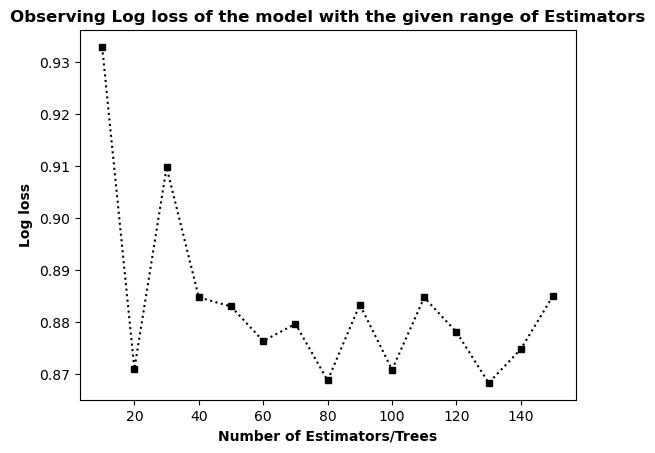

In [51]:
#Visual representation of score pattern
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
ax.plot(Trees,
        Estimated,
        marker = "s",
        markersize = 5,
        color = "black",
        linestyle = "dotted",
        label = "R2score")

ax.set_title("Observing Log loss of the model with the given range of Estimators",
          fontweight = "bold")
ax.set_xlabel("Number of Estimators/Trees",
              fontweight = "bold")
ax.set_ylabel("Log loss",
              fontweight = "bold")
plt.show()

In [52]:
#Testing the predictability of the model on test batch with the highest number of estimators that was also able to produce the highest R2 score
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from boruta import BorutaPy

rf = RandomForestClassifier(n_estimators= 130,
                            max_features = maxfeatures,
                            max_depth = None,
                            random_state = 0)

rf.fit(x_train_encoded, y_train_encoded)
y_test_proba_hat = rf.predict_proba(x_test_encoded)
Eval_scores = log_loss(y_test_encoded, y_test_proba_hat)
print(f"We obtained the logloss of {round(Eval_scores, 4)}, compared to baseline logloss of 0.9348") 

d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


We obtained the logloss of 2.3863, compared to baseline logloss of 0.9348


In [53]:
#Lets retrieve the features that were most important in determining the model 
Feature_Importance = rf.feature_importances_
Feature_Importance = pd.DataFrame(Feature_Importance)
Feature_Importance = Feature_Importance.T
Feature_Importance.columns = x_train_encoded.columns.to_list()
Feature_Importance = Feature_Importance.T
Feature_Importance.reset_index(inplace = True)

Feature_Importance.columns = ["Features", "Significance"]
Feature_Importance.sort_values(by = "Significance", ascending= False, inplace = True)
Feature_Importance = Feature_Importance
Feature_Importance["Proportional Significance"] = Feature_Importance["Significance"]*100
Feature_Importance.set_index("Features", inplace = True)
Feature_Importance.to_csv("Feature Importance SD.csv")
Feature_Importance


,Significance,Proportional Significance
Features,,
Age,0.266872,26.687240
Family size,0.196947,19.694651
Geography_Urban,0.060526,6.052574
Geography_Remote,0.054467,5.446737
Primary occupation_Agriculture,0.052700,5.270002
Educational qualification_Unofficial Education,0.042867,4.286663
Educational qualification_Higher Secondary,0.041014,4.101446
Ethnicity_Chhetri,0.034591,3.459074
Availability of sufficient water for irrigation_No,0.032954,3.295389


C:\Users\prien\AppData\Local\Temp\ipykernel_8744\567090139.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(wrapped_labels)


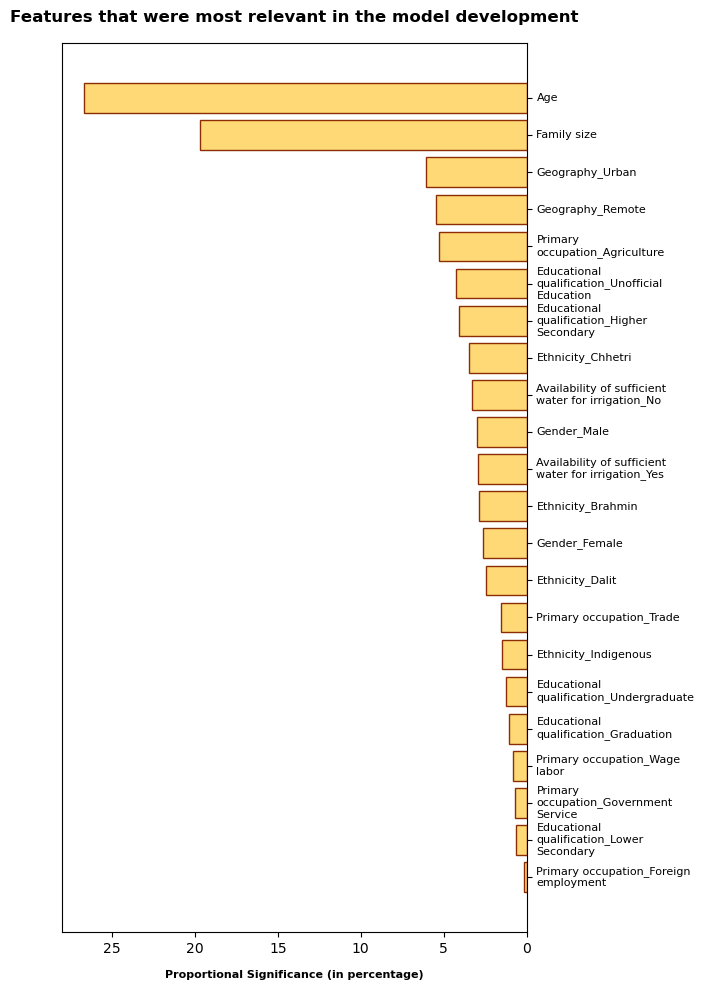

In [65]:
#Lets plot our Feature Significance table to see what feature and category played the top signficant role in determining our not-so-accurate
# predicting model
import matplotlib as mpl
import matplotlib.pyplot as plt
import textwrap

fig, ax = plt.subplots(figsize = (6,10))
ax.barh(Feature_Importance.index, 
        Feature_Importance["Proportional Significance"],
        color = "#fed976",
        edgecolor = "#8c2d04")

ax.invert_yaxis() #for some reason the ascending sorting does not seem to work for bar plotting
ax.invert_xaxis()

ax.yaxis.set_label_position("right")
ax.yaxis.tick_right()

# 5. Titles and Labels
ax.set_title(
    "Features that were most relevant in the model development",
    fontweight="bold",
    pad=15,
)
ax.set_xlabel(
    "Proportional Significance (in percentage)",
    fontsize=8,
    fontweight="black",
    labelpad=10,
)
#ax.set_ylabel("Features", fontsize=8, fontweight="black", labelpad=10)

# 6. Format Y-tick text labels (Right-aligned next to axis line with word wrapping)
wrapped_labels = [textwrap.fill(label, width=28) for label in Feature_Importance.index]
ax.set_yticklabels(wrapped_labels)

for label in ax.get_yticklabels():
    label.set_fontsize(8)
    label.set_ha("left")  # Aligns text cleanly to the right of the vertical axis
    label.set_va("center")

# Clean up layout padding to make room for right-hand text labels
plt.tight_layout()
plt.subplots_adjust(right=0.80)
plt.show()

In [55]:
#Preparing the Classification report
y_test_hat = rf.predict(x_test_encoded) #Retrieving the hard prediction based on the RF model
y_test_hat_unencoded = label_encoder.inverse_transform(y_test_hat) #Reverse transform the data for labelling purpose

from sklearn.metrics import classification_report
print(classification_report(y_test_hat_unencoded, y_test))

                                                             precision    recall  f1-score   support

                  Planting of improved spcies of crops only       0.00      0.00      0.00         0
               Planting of indigenous species of crops only       0.90      0.56      0.69        16
Planting of mix of indigenous and improved species of crops       0.30      0.50      0.38         6

                                                   accuracy                           0.55        22
                                                  macro avg       0.40      0.35      0.36        22
                                               weighted avg       0.74      0.55      0.61        22



d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


#### Support Vector Machine

In [56]:
#Now calculating the distance of the predicted target value from the hyper-plane (i.e., decision boundary)
from sklearn.svm import LinearSVC
from sklearn.metrics import roc_auc_score
from scipy.special import softmax

Estimated = []
C = [0.01, 0.1, 1.0, 10] # arranging exponential parameters 
for values in C:
    svm = LinearSVC(loss = "hinge",
                    multi_class = "ovr",
                    C = values,
                    dual = True,
                    random_state = 0)
    
    svm.fit(x_train_encoded, y_train_encoded)

    y_eval_distance = svm.decision_function(x_eval_encoded)
    y_eval_distance_df = pd.DataFrame(y_eval_distance)
    y_eval_probs = softmax(y_eval_distance_df, axis = 1) # Now turning raw distance in probabilities using softmax

    Eval_scores = roc_auc_score(y_eval_encoded,
                                y_eval_probs,
                                multi_class = "ovr",
                                average = "weighted") # Adjusts for any class size differences in the split
    Estimated.append(Eval_scores)
print(Estimated)  

[np.float64(0.6017316017316017), np.float64(0.5667552144824873), np.float64(0.5618358913813459), np.float64(0.5686245572609209)]


d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please 

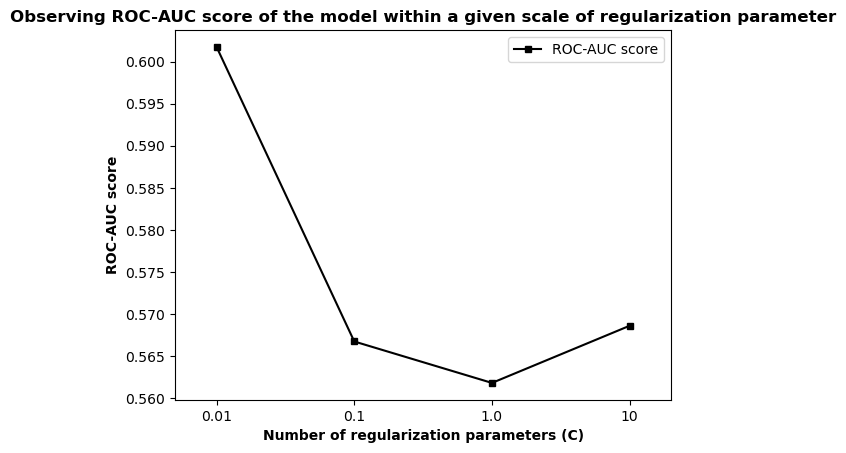

In [57]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
ax.plot(C,
        Estimated,
        marker = "s",
        markersize = 5,
        color = "black",
        label = "ROC-AUC score")

ax.set_title("Observing ROC-AUC score of the model within a given scale of regularization parameter",
             fontweight = "bold")

ax.set_xscale("log")
ax.set_xticks(C)
ax.set_xticklabels(["0.01", "0.1", "1.0", "10"])
ax.minorticks_off()

ax.set_xlim(0.005, 20)
ax.set_xlabel("Number of regularization parameters (C)",
              fontweight = "bold")

ax.set_ylabel("ROC-AUC score",
              fontweight = "bold")
plt.legend()
plt.show()

In [58]:
from sklearn.svm import LinearSVC
from sklearn.metrics import roc_auc_score
from scipy.special import softmax

svm = LinearSVC(loss = "hinge",
                multi_class = "ovr",
                C = 1.0,
                dual = True,
                random_state = 0)

svm.fit(x_train_encoded, y_train_encoded)

y_test_distance = svm.decision_function(x_test_encoded)
y_test_distance_df = pd.DataFrame(y_test_distance)
y_test_probs = softmax(y_test_distance_df, axis = 1) # Now turning raw distance in probabilities using softmax

score = roc_auc_score(y_test_encoded,
                      y_test_probs,
                      multi_class = "ovr",
                      average = "weighted") # Adjusts for any class size differences in the split
print(f"The accuracy of the estimates of the model is {round(score*100, 3)} percent")

The accuracy of the estimates of the model is 82.803 percent


d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [59]:
#Now producing the classification report 
y_test_hat = svm.predict(x_test_encoded) #Retrieving the hard prediction based on the RF model
y_test_hat_unencoded = label_encoder.inverse_transform(y_test_hat) #Reverse transform the data for labelling purpose

from sklearn.metrics import classification_report
print(classification_report(y_test_hat_unencoded, y_test))
#the accuracy appears to be relatively better for each target class than the earlier RF model. Also, the model accuracy is better
#the improvement may be attributed to consolidation of sparse/minor target class for which overall accuracy was zero percent

                                                             precision    recall  f1-score   support

                  Planting of improved spcies of crops only       0.00      0.00      0.00         0
               Planting of indigenous species of crops only       0.90      0.75      0.82        12
Planting of mix of indigenous and improved species of crops       0.70      0.70      0.70        10

                                                   accuracy                           0.73        22
                                                  macro avg       0.53      0.48      0.51        22
                                               weighted avg       0.81      0.73      0.76        22



d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\Anaconda_navigator\envs\RP_env\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [60]:
#Now observing the coefficients of each independent variables that built the SVM model 
Feature_Coefficient = svm.coef_
Feature_Coefficient = pd.DataFrame(Feature_Coefficient)
Feature_Coefficient.columns = x_train_encoded.columns.to_list()
Feature_Coefficient = Feature_Coefficient.T
Feature_Coefficient.reset_index(inplace = True)
Feature_Coefficient.columns = ["Features",
                               "Improved crop varieties only",
                               "Indigenous crop varieties only",
                               "Mixed planting only"]

Feature_Coefficient.set_index("Features", inplace = True)
Feature_Coefficient

,Improved crop varieties only,Indigenous crop varieties only,Mixed planting only
Features,,,
Gender_Female,-0.036885,-2.691859e-06,4.110472e-07
Gender_Male,0.036885,2.691859e-06,-4.110472e-07
Ethnicity_Brahmin,-0.070142,-4.967688e-01,4.967798e-01
Ethnicity_Chhetri,-0.171257,1.442479e-01,-1.442526e-01
Ethnicity_Dalit,0.293705,1.115483e-01,-1.115472e-01
Ethnicity_Indigenous,-0.020582,9.777858e-02,-9.778281e-02
Educational qualification_Graduation,0.066873,-2.376227e-01,2.234716e-01
Educational qualification_Higher Secondary,0.189627,3.379306e-02,-7.969850e-02
Educational qualification_Lower Secondary,0.086145,1.775100e-02,-4.187141e-02


In [61]:
Feature_Coefficient.to_csv("FC SD.csv")

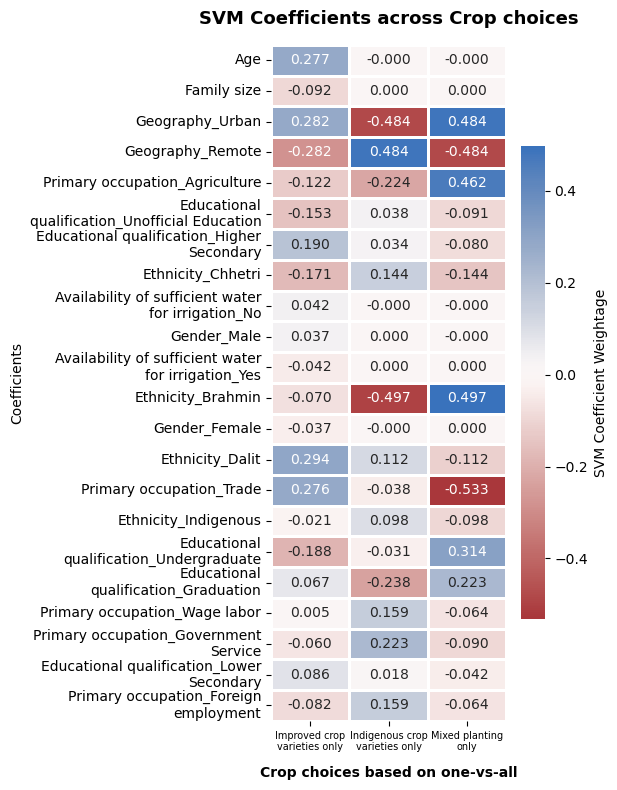

In [62]:
import textwrap
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

order = [
    "Age",
    "Family size",
    "Geography_Urban",
    "Geography_Remote",
    "Primary occupation_Agriculture",
    "Educational qualification_Unofficial Education",
    "Educational qualification_Higher Secondary",
    "Ethnicity_Chhetri",
    "Availability of sufficient water for irrigation_No",
    "Gender_Male",
    "Availability of sufficient water for irrigation_Yes",
    "Ethnicity_Brahmin",
    "Gender_Female",
    "Ethnicity_Dalit",
    "Primary occupation_Trade",
    "Ethnicity_Indigenous",
    "Educational qualification_Undergraduate",
    "Educational qualification_Graduation",
    "Primary occupation_Wage labor",
    "Primary occupation_Government Service",
    "Educational qualification_Lower Secondary",
    "Primary occupation_Foreign employment",
]

Feature_Coefficient = Feature_Coefficient.reindex(order)

# 1. Wrap Y-axis feature labels
wrapped_y_labels = [
    textwrap.fill(label, width=35) for label in Feature_Coefficient.index
]

# 2. Wrap X-axis column labels
wrapped_x_labels = [
    textwrap.fill(label, width=15) for label in Feature_Coefficient.columns
]

plt.figure(figsize=(6, 8))

# 3. Assign heatmap output directly to `ax`
ax = sns.heatmap(
    Feature_Coefficient,
    annot=True,
    fmt=".3f",
    cmap="vlag_r",
    center=0,
    cbar_kws={"label": "SVM Coefficient Weightage", "shrink": 0.7},
    linewidths=0.8,
    linecolor="white",
    xticklabels=wrapped_x_labels,
    yticklabels=wrapped_y_labels,
    square=False,
)

# 4. Turn off all Y-ticks and Y-tick labels
#ax.tick_params(
#    axis="y",
#    which="both",
#    left=False,
#    right=False,
#    labelleft=False,
#    labelright=False,
#)

# 5. Rotate X-ticks
plt.xticks(rotation=0, fontsize=7)

plt.title(
    "SVM Coefficients across Crop choices",
    fontsize=13,
    pad=15,
    fontweight="bold",
)

plt.xlabel(
    "Crop choices based on one-vs-all",
    fontsize=10,
    labelpad=10,
    fontweight="bold",
)

plt.ylabel("Coefficients")

plt.tight_layout()
plt.show()

In [63]:
#Observing the encoded labels for reference
label_names = label_encoder.classes_
for i, values in enumerate(label_names):
    print(i, values)

0 Planting of improved spcies of crops only
1 Planting of indigenous species of crops only
2 Planting of mix of indigenous and improved species of crops


### Supplementary

In [64]:
Ag_dec_SD_ind["Ethnicity"].replace(["Chhetri", "Brahmin"], "Higher-class ethnicity", inplace = True)
Ag_dec_SD_ind["Ethnicity"] = Ag_dec_SD_ind["Ethnicity"].replace("Dalit", "Lower-class ethnicity")
Ag_dec_SD_ind["Ethnicity"] = Ag_dec_SD_ind["Ethnicity"].replace("Indigenous", "Middle-class ethnicity")
Ag_dec_SD_ind["Ethnicity"].value_counts()


C:\Users\prien\AppData\Local\Temp\ipykernel_8744\4070002320.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  Ag_dec_SD_ind["Ethnicity"].replace(["Chhetri", "Brahmin"], "Higher-class ethnicity", inplace = True)


Ethnicity
Higher-class ethnicity    70
Lower-class ethnicity     23
Middle-class ethnicity    15
Name: count, dtype: int64